# Images, masks, meshes and provenance

What must survive the journey from an image array to a geometric model?

Fall 2024.


Predict: which checks should change if the threshold rises, and which should change if both spacings double? This is a synthetic 2D geometry pipeline, not a flow simulation.

{'foreground_pixels': 295, 'triangles': 590, 'area_mm2': 737.5}


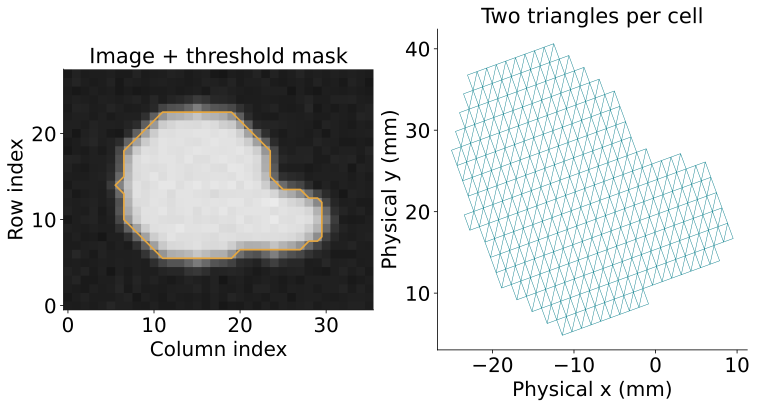

In [1]:
from demo import run
from IPython.display import SVG, display
report = run()
print({k:report[k] for k in ('foreground_pixels','triangles','area_mm2')})
display(SVG(filename='image-mesh.svg'))

Interpret the two coordinate systems. Verify one unrotated point from the worked example. The first component passed to physical_points is column, not row.

[[-15.  -4.]]


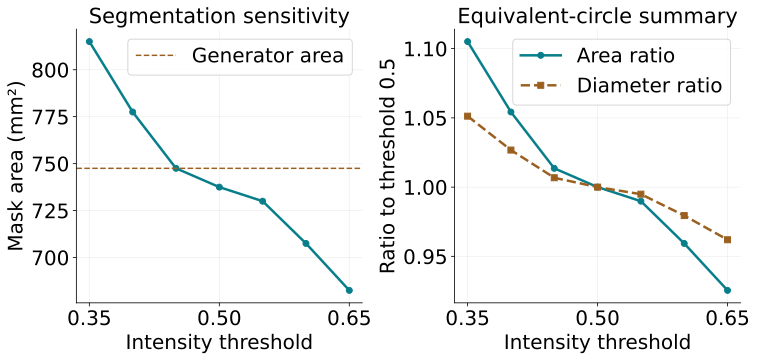

In [2]:
from demo import geometry, physical_points
print(physical_points([[4,3]], geometry(angle_degrees=0)))
display(SVG(filename='geometry-sensitivity.svg'))

Modify: choose a threshold between 0.35 and 0.65, predict the sign of the area change relative to 0.5, then run. Record the choice and whether the component count changed. Do not interpret this range as a confidence interval.

In [3]:
from demo import make_image, segment, mesh_from_mask, signed_areas
from scipy.ndimage import label
image, truth = make_image()
chosen_threshold = 0.55
mask = segment(image, chosen_threshold)
points, triangles = mesh_from_mask(mask, geometry())
print('threshold:', chosen_threshold, 'area mm²:', signed_areas(points, triangles).sum(), 'components:', label(mask)[1])

threshold: 0.55 area mm²: 730.0 components: 1
